# Step 2 — Feature Engineering

This notebook tests the feature ideas collected in `docs/pre_development_research_report.md` (Section 5) against the Step 1 baseline. Every variant is evaluated with the Step 1 protocol: 5 × 3 repeated `StratifiedGroupKFold` on the development data, nested threshold choice, identical folds for every model.

**Decision rule (fixed before running).** A variant is adopted when its mean paired PR-AUC gain over the baseline is positive **and** it is better in at least 12 of the 15 folds (one-sided sign test, p ≈ 0.018). F1, precision and recall are reported alongside but do not decide.

**Stages**
1. **Text representation** — each change applied alone to the baseline: sublinear TF and `min_df`, word bigrams, character n-grams, one TF-IDF per field, adding `requirements` and `benefits`.
2. **Additional features** — each group added alone to the baseline: length/completeness/contact meta features, country, country + state, extra categorical columns, extra binary columns.
3. **Combination** — all adopted changes together, compared with the baseline and with the best single change.
4. **Regularisation** — a small sweep of the SVM's `C` for the selected configuration.

The test set is not used in this notebook.

In [1]:
import sklearn

if sklearn.__version__ != "1.6.1":
    raise RuntimeError(
        f"This notebook uses scikit-learn 1.6.1 (found {sklearn.__version__}). "
        "Install the pinned versions with: pip install -r requirements.txt"
    )

import time
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fakejob.data import load_split
from fakejob.evaluation import compare, passes_rule, repeated_group_cv
from fakejob.features import (
    ALL_TEXT_FIELDS, BASE_BINARY, BASE_CATEGORICAL, EXTRA_BINARY, EXTRA_CATEGORICAL,
    META_COLUMNS, Config, build_pipeline, posting_features,
)

pd.set_option("display.precision", 3)
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

## Data

`posting_features()` adds only row-wise derived columns (joined text, lengths, empty-field flags, counts of the masked `#URL_`, `#EMAIL_`, `#PHONE_` tokens, upper-case ratio, exclamation marks, country and state from `location`). Nothing is learned across rows, so computing it once on the whole dataset does not leak information. Everything that is fitted lives inside the pipeline.

In [2]:
split = load_split()
features = posting_features(split.model_df)

dev_index = split.dev_index
X_dev = features.loc[dev_index]
y_dev = split.y.loc[dev_index]
groups_dev = split.groups.loc[dev_index]
print(f"Development data: {len(dev_index)} postings, {int(y_dev.sum())} fake")

# How strongly do some of the new raw signals relate to the label? (development data only)
def fake_rate(mask):
    return pd.Series({"rows": int(mask.sum()), "fake %": y_dev[mask].mean() * 100})

signals = pd.DataFrame({
    "Company profile empty": fake_rate(X_dev["empty_company_profile"] == 1),
    "Company profile filled": fake_rate(X_dev["empty_company_profile"] == 0),
    "Contains #EMAIL_": fake_rate(X_dev["n_email"] > 0),
    "Contains #PHONE_": fake_rate(X_dev["n_phone"] > 0),
    "Contains #URL_": fake_rate(X_dev["n_url"] > 0),
    "Salary range given": fake_rate(X_dev["has_salary_range"] == 1),
    "All development data": fake_rate(pd.Series(True, index=X_dev.index)),
}).T
display(signals)

country_rates = (
    pd.DataFrame({"rows": X_dev["country"].value_counts(),
                  "fake %": y_dev.groupby(X_dev["country"]).mean() * 100})
    .sort_values("rows", ascending=False).head(10)
)
country_rates

Development data: 15001 postings, 724 fake


,rows,fake %
Company profile empty,2798.0,17.298
Company profile filled,12203.0,1.967
Contains #EMAIL_,1094.0,12.066
Contains #PHONE_,457.0,14.442
Contains #URL_,4788.0,4.741
Salary range given,2400.0,8.000
All development data,15001.0,4.826


,rows,fake %
country,,
US,8960,6.719
GB,1930,1.088
GR,803,0.000
CA,378,3.175
DE,323,0.000
Unknown,296,5.405
NZ,275,0.000
IN,234,1.709
AU,180,19.444


## Helper

`run()` evaluates one configuration on the shared folds and stores the fold-level results. Character n-gram variants use fewer parallel workers because their TF-IDF matrices are large. `judge()` compares a candidate with a reference result and applies the decision rule.

In [3]:
results = {}
METRICS = ["average_precision", "roc_auc", "f1", "precision", "recall"]

def run(name, config):
    n_jobs = 4 if config.char_ngrams else -1
    start = time.time()
    result = repeated_group_cv(
        build_pipeline(config), X_dev, y_dev, groups_dev, name=name,
        n_splits=5, n_repeats=3, inner_splits=3, seed=0, n_jobs=n_jobs,
    )
    result.config = config
    results[name] = result
    result.folds.to_csv(RESULTS_DIR / f"step2_{name}_folds.csv", index=False)
    print(f"{name}: {time.time() - start:.0f}s")
    return result

def judge(reference, candidates):
    rows = []
    for cand in candidates:
        comparison = compare(reference, cand, metrics=METRICS)
        ap, f1 = comparison.loc["average_precision"], comparison.loc["f1"]
        rows.append({
            "variant": cand.name,
            "PR-AUC": f"{cand.folds['average_precision'].mean():.3f} ± {cand.folds['average_precision'].std():.3f}",
            "Δ PR-AUC": ap["mean_diff"],
            "PR-AUC wins": ap["folds_improved"],
            "F1": f"{cand.folds['f1'].mean():.3f} ± {cand.folds['f1'].std():.3f}",
            "Δ F1": f1["mean_diff"],
            "F1 wins": f1["folds_improved"],
            "Δ recall": comparison.loc["recall", "mean_diff"],
            "adopted": passes_rule(comparison),
        })
    return pd.DataFrame(rows).set_index("variant")

## Baseline

`Config()` with default values rebuilds the Step 1 reference SVM. The assertion checks that the fold results are identical to those saved in Step 1.

In [4]:
base = Config()
baseline = run("baseline", base)

step1 = pd.read_csv(RESULTS_DIR / "step1_reference_svm_folds.csv")
assert np.allclose(baseline.folds[METRICS].values, step1[METRICS].values)
baseline.summary().to_frame("Baseline (mean ± std)")

baseline: 36s


,Baseline (mean ± std)
threshold,-0.069 ± 0.049
average_precision,0.825 ± 0.057
roc_auc,0.978 ± 0.008
f1,0.748 ± 0.069
precision,0.786 ± 0.055
recall,0.719 ± 0.100


## Stage 1: Text Representation

| Variant | Change |
|---|---|
| `sublinear_mindf2` | `sublinear_tf=True` (1 + log tf) and `min_df=2` |
| `word_1_2` | word unigrams + bigrams, `min_df=2` |
| `char_3_5` | an extra `char_wb` TF-IDF with 3–5 character n-grams |
| `per_field` | separate TF-IDF for title, company profile and description |
| `all_text` | `requirements` and `benefits` added to the text |

In [5]:
stage1_configs = {
    "sublinear_mindf2": base.but(sublinear_tf=True, min_df=2),
    "word_1_2": base.but(word_ngrams=(1, 2), min_df=2),
    "char_3_5": base.but(char_ngrams=(3, 5)),
    "per_field": base.but(per_field=True),
    "all_text": base.but(text_fields=tuple(ALL_TEXT_FIELDS)),
}
stage1 = [run(name, config) for name, config in stage1_configs.items()]
stage1_table = judge(baseline, stage1)
stage1_table

sublinear_mindf2: 30s


word_1_2: 75s


char_3_5: 561s


per_field: 44s


all_text: 40s


,PR-AUC,Δ PR-AUC,PR-AUC wins,F1,Δ F1,F1 wins,Δ recall,adopted
variant,,,,,,,,
sublinear_mindf2,0.841 ± 0.053,0.016,14/15,0.746 ± 0.074,-2.756e-03,10/15,2.130e-02,True
word_1_2,0.861 ± 0.050,0.036,14/15,0.784 ± 0.059,3.516e-02,14/15,1.318e-02,True
char_3_5,0.851 ± 0.050,0.026,15/15,0.777 ± 0.059,2.874e-02,12/15,2.825e-02,True
per_field,0.822 ± 0.051,-0.003,6/15,0.753 ± 0.049,4.958e-03,8/15,1.626e-03,False
all_text,0.828 ± 0.062,0.002,8/15,0.749 ± 0.065,2.729e-05,7/15,-5.525e-04,False


## Stage 2: Additional Features

| Variant | Added to the baseline |
|---|---|
| `meta` | log lengths of each text field, empty-field flags, counts of `#URL_` / `#EMAIL_` / `#PHONE_`, upper-case ratio, exclamation marks per 1,000 characters (scaled to [0, 1]) |
| `country` | one-hot country from `location` |
| `country_state` | one-hot country + state from `location` |
| `extra_categorical` | `required_education`, `function`, `industry` |
| `extra_binary` | `has_questions`, salary range given |

In [6]:
stage2_configs = {
    "meta": base.but(meta=True),
    "country": base.but(location="country"),
    "country_state": base.but(location="country_state"),
    "extra_categorical": base.but(categorical=tuple(BASE_CATEGORICAL + EXTRA_CATEGORICAL)),
    "extra_binary": base.but(binary=tuple(BASE_BINARY + EXTRA_BINARY)),
}
stage2 = [run(name, config) for name, config in stage2_configs.items()]
stage2_table = judge(baseline, stage2)
stage2_table

meta: 35s


country: 30s


country_state: 29s


extra_categorical: 31s


extra_binary: 31s


,PR-AUC,Δ PR-AUC,PR-AUC wins,F1,Δ F1,F1 wins,Δ recall,adopted
variant,,,,,,,,
meta,0.824 ± 0.056,-1.336e-03,6/15,0.752 ± 0.066,3.399e-03,6/15,5.354e-04,False
country,0.825 ± 0.052,-5.744e-04,8/15,0.746 ± 0.073,-2.655e-03,7/15,1.368e-02,False
country_state,0.822 ± 0.052,-3.546e-03,8/15,0.741 ± 0.064,-7.522e-03,6/15,1.132e-02,False
extra_categorical,0.817 ± 0.056,-7.680e-03,8/15,0.760 ± 0.059,1.134e-02,8/15,1.568e-02,False
extra_binary,0.824 ± 0.058,-1.617e-03,6/15,0.748 ± 0.064,-4.266e-04,6/15,1.354e-02,False


## Stage 3: Combination

All adopted changes are applied together. Two changes are alternatives and cannot be combined: `country` and `country_state` (only the one with the higher PR-AUC is kept), and `sublinear_mindf2` and `word_1_2` both set the word TF-IDF options (their settings are merged: sublinear TF with the n-gram range of `word_1_2`).

The combination is accepted only if it also passes the rule against the best single adopted variant; otherwise the best single variant is carried forward.

In [7]:
adopted = [name for table in (stage1_table, stage2_table) for name in table.index[table["adopted"]]]
print("Adopted single changes:", adopted or "none")

all_configs = {**stage1_configs, **stage2_configs}
if "country" in adopted and "country_state" in adopted:
    weaker = min(["country", "country_state"],
                 key=lambda n: results[n].folds["average_precision"].mean())
    adopted.remove(weaker)
    print("Dropped the weaker location variant:", weaker)

changes = {}
for name in adopted:
    config = all_configs[name]
    for field in Config.__dataclass_fields__:
        value = getattr(config, field)
        if value != getattr(base, field):
            changes[field] = max(changes.get(field, value), value) if field == "min_df" else value
combined_config = base.but(**changes)
print("Combined configuration changes:", changes)

if len(adopted) >= 2:
    combined = run("combined", combined_config)
    best_single = max((results[n] for n in adopted),
                      key=lambda r: r.folds["average_precision"].mean())
    display(judge(baseline, [combined]))
    vs_best = judge(best_single, [combined])
    print(f"Combined vs best single change ({best_single.name}):")
    display(vs_best)
    selected = combined if vs_best["adopted"].iloc[0] else best_single
elif len(adopted) == 1:
    selected = results[adopted[0]]
else:
    selected = baseline
print("Selected configuration:", selected.name)

Adopted single changes: ['sublinear_mindf2', 'word_1_2', 'char_3_5']
Combined configuration changes: {'sublinear_tf': True, 'min_df': 2, 'word_ngrams': (1, 2), 'char_ngrams': (3, 5)}


combined: 696s


,PR-AUC,Δ PR-AUC,PR-AUC wins,F1,Δ F1,F1 wins,Δ recall,adopted
variant,,,,,,,,
combined,0.871 ± 0.047,0.045,15/15,0.789 ± 0.057,0.041,14/15,0.033,True


Combined vs best single change (word_1_2):


,PR-AUC,Δ PR-AUC,PR-AUC wins,F1,Δ F1,F1 wins,Δ recall,adopted
variant,,,,,,,,
combined,0.871 ± 0.047,0.01,14/15,0.789 ± 0.057,0.006,10/15,0.02,True


Selected configuration: combined


## Stage 4: Regularisation Strength `C`

`C` controls how strongly the SVM fits the training data (smaller `C` = more regularisation). It is varied for the selected configuration only. A different `C` is adopted only if it passes the rule against the selected configuration at `C = 1`.

In [8]:
c_results = []
for c_value in [0.1, 0.3, 3.0]:
    name = f"{selected.name}_C{c_value:g}"
    c_results.append(run(name, selected.config.but(C=c_value)))
c_table = judge(selected, c_results)
display(c_table)

passing = [r for r in c_results if c_table.loc[r.name, "adopted"]]
final = max(passing, key=lambda r: r.folds["average_precision"].mean()) if passing else selected
print("Final Step 2 configuration:", final.name)
print(final.config)

combined_C0.1: 569s


combined_C0.3: 614s


combined_C3: 869s


,PR-AUC,Δ PR-AUC,PR-AUC wins,F1,Δ F1,F1 wins,Δ recall,adopted
variant,,,,,,,,
combined_C0.1,0.854 ± 0.047,-1.664e-02,1/15,0.754 ± 0.071,-0.036,2/15,-3.132e-02,False
combined_C0.3,0.868 ± 0.046,-2.797e-03,4/15,0.790 ± 0.056,0.001,7/15,-1.156e-02,False
combined_C3,0.870 ± 0.048,-9.573e-04,7/15,0.793 ± 0.052,0.004,9/15,9.429e-04,False


Final Step 2 configuration: combined
Config(text_fields=('title', 'company_profile', 'description'), per_field=False, word_ngrams=(1, 2), sublinear_tf=True, min_df=2, char_ngrams=(3, 5), categorical=('employment_type', 'required_experience'), binary=('telecommuting', 'has_company_logo'), meta=False, location=None, C=1.0, max_iter=5000)


## Final Step 2 Configuration vs Baseline

,baseline,combined
threshold,-0.069 ± 0.049,-0.272 ± 0.070
average_precision,0.825 ± 0.057,0.871 ± 0.047
roc_auc,0.978 ± 0.008,0.984 ± 0.007
f1,0.748 ± 0.069,0.789 ± 0.057
precision,0.786 ± 0.055,0.834 ± 0.065
recall,0.719 ± 0.100,0.752 ± 0.066


,baseline,candidate,mean_diff,std_diff,folds_improved
metric,,,,,
average_precision,0.825,0.871,0.045,0.020,15/15
roc_auc,0.978,0.984,0.007,0.004,15/15
f1,0.748,0.789,0.041,0.035,14/15
precision,0.786,0.834,0.048,0.071,11/15
recall,0.719,0.752,0.033,0.056,9/15


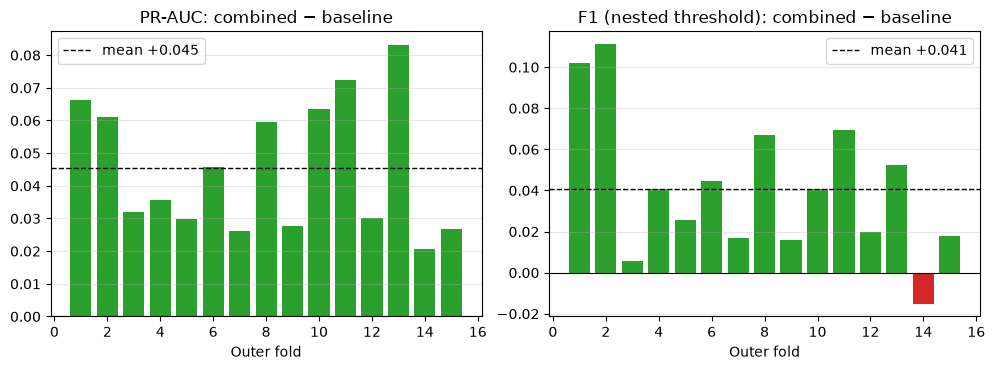

In [9]:
final_vs_baseline = compare(baseline, final, metrics=METRICS)
display(pd.concat([baseline.summary(), final.summary()], axis=1).dropna())
display(final_vs_baseline)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, metric, label in zip(axes, ["average_precision", "f1"], ["PR-AUC", "F1 (nested threshold)"]):
    diff = final.folds[metric].values - baseline.folds[metric].values
    ax.bar(range(1, len(diff) + 1), diff, color=["tab:green" if d > 0 else "tab:red" for d in diff])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axhline(diff.mean(), color="black", linestyle="--", linewidth=1, label=f"mean {diff.mean():+.3f}")
    ax.set_xlabel("Outer fold")
    ax.set_title(f"{label}: {final.name} − baseline")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

## Overview of All Variants

In [10]:
overview = pd.concat([
    judge(baseline, [results[n] for n in results if n != "baseline"]),
])
overview.to_csv(RESULTS_DIR / "step2_overview.csv")
overview.sort_values("Δ PR-AUC", ascending=False)

,PR-AUC,Δ PR-AUC,PR-AUC wins,F1,Δ F1,F1 wins,Δ recall,adopted
variant,,,,,,,,
combined,0.871 ± 0.047,4.539e-02,15/15,0.789 ± 0.057,4.096e-02,14/15,3.305e-02,True
combined_C3,0.870 ± 0.048,4.443e-02,15/15,0.793 ± 0.052,4.472e-02,13/15,3.400e-02,True
combined_C0.3,0.868 ± 0.046,4.260e-02,15/15,0.790 ± 0.056,4.197e-02,13/15,2.149e-02,True
word_1_2,0.861 ± 0.050,3.565e-02,14/15,0.784 ± 0.059,3.516e-02,14/15,1.318e-02,True
combined_C0.1,0.854 ± 0.047,2.875e-02,13/15,0.754 ± 0.071,5.380e-03,7/15,1.734e-03,True
char_3_5,0.851 ± 0.050,2.553e-02,15/15,0.777 ± 0.059,2.874e-02,12/15,2.825e-02,True
sublinear_mindf2,0.841 ± 0.053,1.620e-02,14/15,0.746 ± 0.074,-2.756e-03,10/15,2.130e-02,True
all_text,0.828 ± 0.062,2.466e-03,8/15,0.749 ± 0.065,2.729e-05,7/15,-5.525e-04,False
country,0.825 ± 0.052,-5.744e-04,8/15,0.746 ± 0.073,-2.655e-03,7/15,1.368e-02,False


## Findings

All numbers are mean ± std over the same 15 outer folds (5 folds × 3 repeats) on the development data. A change was adopted only if it passed the Step 1 decision rule: a positive mean paired PR-AUC gain and a win in at least 12 of 15 folds.

**1. Text representation is where the gains are.** Three of the five Stage 1 changes passed the rule:

| Change | PR-AUC | Δ PR-AUC (wins) | F1 |
|---|---|---|---|
| Baseline | 0.825 ± 0.057 | – | 0.748 ± 0.069 |
| `word_1_2` (word bigrams) | 0.861 ± 0.050 | +0.036 (14/15) | 0.784 ± 0.059 |
| `char_3_5` (char n-grams) | 0.851 ± 0.050 | +0.026 (15/15) | 0.777 ± 0.059 |
| `sublinear_mindf2` | 0.841 ± 0.053 | +0.016 (14/15) | 0.746 ± 0.074 |

Word bigrams capture short phrases (for example "work from", "data entry") that single words miss; character n-grams add robustness to spelling and formatting variation. `sublinear_tf` improves ranking but not F1 on its own.

**2. A separate TF-IDF per field and adding `requirements` / `benefits` did not help** (`per_field` −0.003, 6/15; `all_text` +0.002, 8/15). Splitting the vocabulary across fields gives each field fewer training examples per term, and the two extra fields add little information that the core fields do not already contain.

**3. None of the extra structured features passed the rule.** `meta`, `country`, `country_state`, `extra_categorical` and `extra_binary` all changed PR-AUC by less than ±0.008 and won in at most 8 of 15 folds. The signals seen in the data tables above (empty company profile, `#EMAIL_` / `#PHONE_` tokens, Australia) are real, but the TF-IDF features already capture most of them: an empty `company_profile` changes the joined text, and contact tokens appear as words. In particular, the location features give no measurable gain, so the risk of the model learning geography instead of fraud cues does not need to be taken.

**4. The adopted changes are complementary.** The combination (`word_ngrams=(1, 2)`, `char_ngrams=(3, 5)`, `sublinear_tf=True`, `min_df=2`) reached PR-AUC 0.871 ± 0.047. It beat the baseline in 15/15 folds and the best single change (`word_1_2`) in 14/15 folds (+0.010), so it was selected.

**5. `C = 1` stays.** For the combined configuration, `C = 0.1` was clearly worse (−0.017, 1/15), and `C = 0.3` and `C = 3` were within noise (−0.003 and −0.001). The default value is kept. (The `adopted` column in the overview table compares every variant with the baseline; the `C` variants were judged against the combined configuration in Stage 4 and rejected there.)

**6. Final Step 2 model vs baseline:**

| Metric | Baseline | Step 2 | Δ (wins) |
|---|---|---|---|
| PR-AUC | 0.825 ± 0.057 | **0.871 ± 0.047** | +0.045 (15/15) |
| ROC AUC | 0.978 ± 0.008 | 0.984 ± 0.007 | +0.007 (15/15) |
| F1 | 0.748 ± 0.069 | **0.789 ± 0.057** | +0.041 (14/15) |
| Precision | 0.786 ± 0.055 | 0.834 ± 0.065 | +0.048 (11/15) |
| Recall | 0.719 ± 0.100 | 0.752 ± 0.066 | +0.033 (9/15) |

The gain is consistent across folds, not driven by a few lucky splits. The fold-to-fold standard deviation also became smaller. The chosen thresholds moved from about −0.07 to about −0.27, because the scale of the SVM scores changes with the feature set; this is why the threshold is chosen inside each fold rather than reused from the old model.

**Cost and limitations.** The character n-gram TF-IDF makes the model about 15–20 times slower to train (about 11 minutes for the full CV instead of 36 seconds) and much larger in memory. All selection was done on development CV; the held-out test set has not been used and remains reserved for Step 5. Many variants were tried on the same folds, so the selected model's CV score is slightly optimistic; the size and consistency of the gain (15/15 folds) make it unlikely to be a selection artefact.

**Next step (Step 3):** use this configuration as the new baseline for calibration, sentence-embedding features and LightGBM stacking.